# Semantic signal in the graph's metadata: what exists, and can clustering use it?

P3 asks that super-nodes be coherent in **meaning**, not only in structure. This notebook checks what semantic information the TKH export itself carries, and whether a clustering algorithm can use it meaningfully.

The scope is text that ships with the graph: no downloads and no external models. Reusable code lives in `tkh/semantic.py` (text and vectors) and `tkh/evaluate/groundtruth.py` (ground-truth name matching).

The notebook asks four questions:
1. **What is there?** Text fields by node type, their length and their noise.
2. **What does lexical similarity encode?** Node type, paper identity, links across papers, duplicates.
3. **Does it agree with an independent reference beyond chance?** This uses curated ground-truth groups, compared against a null model.
4. **Does it support clustering?** A trial clustering on semantics alone.

Inputs come from the run config (`configs/default.toml` or `$TKH_CONFIG`). The commentary describes the provided export.

In [1]:
import sys, itertools, collections
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "tkh").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import roc_auc_score

from tkh.config import load_config
from tkh.io import load
from tkh import semantic as sm
from tkh.evaluate.groundtruth import load_ground_truth, question_targets

pd.set_option("display.precision", 3); pd.set_option("display.max_colwidth", 70)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
print(f"python {sys.version.split()[0]}, pandas {pd.__version__}, matplotlib {matplotlib.__version__}")

cfg = load_config()
FIG = cfg.figures_dir; FIG.mkdir(parents=True, exist_ok=True)
tkh = load(cfg)
N = tkh.nodes
CORE = sorted(N.index[N["type"].isin(sm.CONCEPT_TYPES)])
TY = N.loc[CORE, "type"].to_numpy(dtype=object)
ARTS = [set(N.at[v, "prov_articles"]) for v in CORE]
POS = {v: i for i, v in enumerate(CORE)}
print(f"{len(N)} nodes; {len(CORE)} concept nodes ({', '.join(sm.CONCEPT_TYPES)})")

python 3.12.11, pandas 3.0.6, matplotlib 3.11.2
5798 nodes; 3980 concept nodes (method, task, problem, technique, component, dataset, metric)


## 1. Inventory: which text exists, per node type

Every node has a `surface_form`, its name as extracted. Some method nodes also carry an undocumented `aliases` list (e.g. 'Materials Graph Network' has the alias 'MEGNet').

"Attached text" is text the export links to a node through its edges:
- the sentences of `claims` edges the node belongs to;
- the future-topic sentences of the paper that presents it;
- the free-text `metric` / `task` / `domain` attributes of its `evaluated_on` edges.

There are no abstracts or descriptions anywhere in the export.

In [2]:
att = sm.attached_text(tkh)
rows = []
for t, g in N.groupby("type"):
    tok = g["surface_form"].map(lambda s: len(sm.clean(s).split()))
    rows.append({"type": t, "nodes": len(g), "median tokens": tok.median(), "share ≤ 2 tokens": (tok <= 2).mean(),
                 "share with aliases": g["aliases"].map(lambda a: isinstance(a, list) and len(a) > 0).mean() if "aliases" in g else 0.0,
                 "share with attached text": np.mean([len(att.get(v, [])) > 0 for v in g.index]),
                 "concept type": t in sm.CONCEPT_TYPES})
inv = pd.DataFrame(rows).set_index("type").sort_values("nodes", ascending=False)
inv

,nodes,median tokens,share ≤ 2 tokens,share with aliases,share with attached text,concept type
type,,,,,,
technique,962,3.0,0.238,0.000,0.000,True
component,855,3.0,0.297,0.000,0.000,True
task,732,3.0,0.164,0.000,0.000,True
claim,690,24.0,0.000,0.000,0.000,False
problem,634,5.0,0.069,0.000,0.000,True
cited_work,580,1.0,0.733,0.000,0.000,False
method,448,3.0,0.493,0.179,0.123,True
author,318,2.0,0.789,0.000,0.000,False
dataset,259,2.0,0.618,0.000,0.915,True


In [3]:
ex = (N[N["type"].isin(sm.CONCEPT_TYPES)].groupby("type")["surface_form"]
      .apply(lambda s: " | ".join(s.sort_values(key=lambda x: x.str.len()).iloc[[0, len(s) // 2, -1]].str[:45])))
ex.to_frame("shortest | median-length | longest name")

,shortest | median-length | longest name
type,
component,EFA | Task-specific output heads | Integrable deep neural network ...
dataset,S | Diatomics OMol | Binary inorganic solid materials melting temp
method,LLM | Metropolis Monte Carlo | Integrable Deep Neural Network (IDN...
metric,F1 | log MSD Li MAE | successful adsorption energy calculations
problem,Data scarcity | Underestimated sp3 concentration in ta-C | Inaccur...
task,S2EF | machine learning for molecules | Accelerated molecular dyna...
technique,DeNS | efficient graph construction | combination with conservativ...


What the inventory shows:
- **Concept nodes have only their names.** The median name is 2–5 tokens. Method, dataset, metric and cited-work names are mostly 1–3 tokens, often proper names ('SchNet', 'QM9', 'MAE').
- **Attached text is narrow.** Datasets and metrics inherit evaluation strings ('energy MAE', 'materials science'), and only the presented method of each paper inherits claim sentences.
- **Sentence-length text exists only on non-concept nodes:** claims, future topics and article titles.

Two sources are deliberately not used as node text:
- **Article titles.** A title is shared by every node of its paper, so adding it would re-encode "same paper", the structural signal.
- **`ground_truth.json`.** It is evaluation material and is used only in §4, as an independent reference.

Names are also noisy. The cell below counts the noise. `sm.clean` handles the first item: it applies NFKC and then maps Unicode dashes and spaces to ASCII. The order matters, because NFKC alone turns U+2011 into U+2010, not '-'.

In [4]:
sf = N["surface_form"]
noise = {
    "non-ASCII characters (e.g. U+2011 hyphen)": int((~sf.map(str.isascii)).sum()),
    "identifier-like names (underscore, no space)": int(sf.str.fullmatch(r"\S*_\S*").sum()),
    "single-token names among concept nodes": int(N.loc[CORE, "surface_form"].map(lambda s: len(sm.clean(s).split()) == 1).sum()),
}
print(noise)
print("identifier-like examples:", list(sf[sf.str.fullmatch(r"\S*_\S*")].head(5)))

{'non-ASCII characters (e.g. U+2011 hyphen)': 1028, 'identifier-like names (underscore, no space)': 8, 'single-token names among concept nodes': 295}
identifier-like examples: ['ml_multiscale_modeling_perspective', 'MLIP_framework_analysis', 'MAE_energy_meV', 'MAE_ωmax', 'MAE_Kbulk']


## 2. Representations and coverage

The representations are lexical only. Word TF-IDF matches whole terms. Character 3–5-gram TF-IDF within word boundaries is robust to hyphenation, plurals and spacing variants ('TensorField' vs 'Tensor Field'). Each is computed on:
- **name:** surface form plus aliases;
- **context:** name plus attached text.

The **LSA** variant projects the TF-IDF matrix to 100 dense dimensions with truncated SVD. Similarity is cosine throughout. Coverage here asks whether a node has any reasonably similar neighbour at all.

In [5]:
REPS = {}
for mode in ("name", "context"):
    for kind in ("word", "char"):
        X, vec = sm.vectorize(sm.node_texts(tkh, CORE, mode), kind)
        REPS[(mode, kind, "raw")] = (X, len(vec.vocabulary_))
        REPS[(mode, kind, "LSA100")] = (sm.lsa(X, 100), 100)
SIMS = {}
cov = []
for key, (Z, dim) in REPS.items():
    S = sm.cosine(Z); np.fill_diagonal(S, -1); SIMS[key] = S
    mx = S.max(axis=1)
    cov.append({"text": key[0], "tf-idf": key[1], "repr": key[2], "features": dim,
                "median best-neighbour cosine": np.median(mx), "share best ≥ 0.5": (mx >= 0.5).mean()})
pd.DataFrame(cov).set_index(["text", "tf-idf", "repr"])

features  median best-neighbour cosine  \
text    tf-idf repr                                             
name    word   raw         2942                         0.614   
               LSA100       100                         0.976   
        char   raw        23525                         0.664   
               LSA100       100                         0.904   
context word   raw         4552                         0.618   
               LSA100       100                         0.972   
        char   raw        34882                         0.673   
               LSA100       100                         0.902   

                       share best ≥ 0.5  
text    tf-idf repr                      
name    word   raw                0.675  
               LSA100             0.995  
        char   raw                0.782  
               LSA100             0.998  
context word   raw                0.674  
               LSA100             0.994  
        char   raw                0.786  
               LSA100             0.999

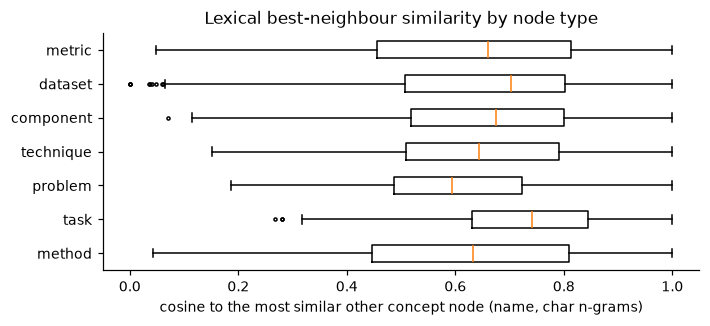

In [6]:
best = SIMS[("name", "char", "raw")].max(axis=1)
order = [t for t in sm.CONCEPT_TYPES]
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.boxplot([best[TY == t] for t in order], orientation="horizontal" if tuple(map(int, matplotlib.__version__.split(".")[:2])) >= (3, 10) else None,
           **({} if tuple(map(int, matplotlib.__version__.split(".")[:2])) >= (3, 10) else {"vert": False}), flierprops={"markersize": 2})
ax.set_yticks(range(1, len(order) + 1), order)
ax.set(xlabel="cosine to the most similar other concept node (name, char n-grams)",
       title="Lexical best-neighbour similarity by node type")
fig.savefig(FIG / "sem_best_neighbour.png"); plt.show()

Most concept nodes have a close lexical neighbour. The next sections ask what such a neighbour **means**.

LSA cosines are not on the same scale as raw TF-IDF cosines. Densification raises all similarities, so nearly every node gets a "neighbour ≥ 0.5". Thresholded statistics should therefore be compared within a representation, not across.

## 3. What lexical similarity encodes

**Nearest neighbours.** Examples are chosen by code: for each of four types, the non-hub node that appears in the most papers. The representation is name + character n-grams.

In [7]:
S = SIMS[("name", "char", "raw")]
n_art = N.loc[CORE, "prov_articles"].map(len)
hub = n_art > 0.2 * len(tkh.articles)
rows = []
for t in ("method", "dataset", "task", "technique"):
    cand = n_art[(N.loc[CORE, "type"] == t) & ~hub].sort_values(ascending=False)
    for v in cand.index[:2]:
        i = POS[v]; top = np.argsort(-S[i])[:4]
        rows.append({"node": f"{N.at[v, 'surface_form'][:30]} [{t}, {n_art[v]} papers]",
                     "nearest neighbours (cosine)": "; ".join(f"{N.at[CORE[j], 'surface_form'][:24]} [{TY[j]}] {S[i, j]:.2f}" for j in top)})
pd.DataFrame(rows)

,node,nearest neighbours (cosine)
0,"density functional theory [method, 10 papers]",density functional theor [task] 1.00; density functional pertu [me...
1,"Neural Equivariant Interatomic [method, 8 papers]",Equivariant interatomic [method] 0.79; interatomic potentials [ta...
2,"Matbench Discovery [dataset, 4 papers]",Matbench Discovery [method] 1.00; Matbench Discovery bench [method...
3,"Materials Project [dataset, 3 papers]",Materials Project [method] 0.92; Materials Project format [dataset...
4,"Molecular dynamics simulations [task, 10 papers]",Molecular dynamics simul [task] 0.96; NVE molecular dynamics s [ta...
5,"Force prediction [task, 9 papers]",Atomic force prediction [problem] 0.79; atomic force prediction [t...
6,"Gradient clipping [technique, 4 papers]",Gradient norm clipping [technique] 0.91; Gradient predictions [com...
7,"Gaussian radial basis function [technique, 3 papers]",Gaussian radial basis fu [component] 1.00; Radial functions with G...


**Proper names.** Below are methods whose name is a single token (e.g. an acronym) and that appear in at least 3 papers, with their nearest neighbours.

In [8]:
proper = [v for v in CORE if N.at[v, "type"] == "method" and len(sm.clean(N.at[v, "surface_form"]).split()) == 1
          and n_art[v] >= 3]
rows = []
for v in sorted(proper, key=lambda v: -n_art[v])[:6]:
    i = POS[v]; top = np.argsort(-S[i])[:4]
    rows.append({"method": f"{N.at[v, 'surface_form']} [{n_art[v]} papers]",
                 "nearest neighbours (cosine)": "; ".join(f"{N.at[CORE[j], 'surface_form'][:22]} [{TY[j]}] {S[i, j]:.2f}" for j in top)})
pd.DataFrame(rows)

,method,nearest neighbours (cosine)
0,SchNet [7 papers],ænet [method] 0.11; M3GNet [method] 0.10; M3GNet [component] 0.10;...
1,MACE-MP-0 [7 papers],MACE-MP-0 [component] 1.00; ACE with message passi [method] 0.15; ...
2,PaiNN [5 papers],ChiroPaiNN [method] 0.47; Modified PaiNN flow ap [component] 0.45;...
3,EquiformerV2 [5 papers],Equiformer [method] 0.75; Equivariant Transforme [method] 0.25; Eq...
4,DimeNet [5 papers],DimeNet++ [method] 0.62; Dimensionality reducti [technique] 0.29; ...
5,NequIP [4 papers],Neural Equivariant Int [method] 0.55; Modified NequIP archit [comp...


The pattern:
- **Descriptive names work.** 'molecular dynamics', 'message passing' and 'formation energy' find genuinely related entities across types.
- **Proper names only find their own family.** A single-token method name finds three kinds of neighbour:
  - the same entity under another type (e.g. a component with the same name);
  - its own name variants and aliases ('DimeNet' → 'DimeNet++', 'EquiformerV2' → 'Equiformer');
  - weak matches on shared fragments, such as a '-Net' suffix.

  It never finds a related method from another family. A lexical signal cannot know that two differently named architectures are both interatomic-potential models.

The next cell measures three things systematically:
- **Type:** how often the 10 nearest neighbours share the node's type, against the base rate.
- **Paper:** how often they come from the same paper, against random pairs.
- **New links:** how often a strong neighbour (cosine ≥ 0.5) comes from a different paper, i.e. a link that structure alone could not provide.

In [9]:
def encodes(S, k=10, seed=0):
    nn = np.argsort(-S, axis=1)[:, :k]
    rnd = np.random.default_rng(seed).integers(0, len(CORE), nn.shape)
    share_art = lambda idx: np.mean([[len(ARTS[i] & ARTS[j]) > 0 for j in row] for i, row in enumerate(idx)])
    top1 = np.argmax(S, axis=1); strong = S[np.arange(len(CORE)), top1] >= 0.5
    return {"kNN same type": (TY[nn] == TY[:, None]).mean(),
            "same type by chance": sum((c / len(TY)) ** 2 for c in collections.Counter(TY).values()),
            "kNN same paper": share_art(nn), "same paper, random pairs": share_art(rnd),
            "nodes with a strong neighbour": strong.mean(),
            "…of which from a different paper": np.mean([len(ARTS[i] & ARTS[top1[i]]) == 0 for i in np.where(strong)[0]])}
pd.DataFrame({f"{k[0]}/{k[1]}/{k[2]}": encodes(S) for k, S in SIMS.items() if k[0] == "name"}).T

,kNN same type,same type by chance,kNN same paper,"same paper, random pairs",nodes with a strong neighbour,…of which from a different paper
name/word/raw,0.392,0.181,0.210,0.033,0.675,0.481
name/word/LSA100,0.411,0.181,0.164,0.033,0.995,0.692
name/char/raw,0.427,0.181,0.227,0.033,0.782,0.504
name/char/LSA100,0.413,0.181,0.174,0.033,0.998,0.670


In [10]:
S = SIMS[("name", "char", "raw")]
iu = np.triu_indices(len(CORE), 1)
v = S[iu]
dup = v >= 0.9
print(f"pairs with cosine ≥ 0.9: {dup.sum()}; of these across two node types: {np.mean(TY[iu[0][dup]] != TY[iu[1][dup]]):.0%}")
top = np.argsort(-v)[:3000]
seen = [(CORE[iu[0][e]], CORE[iu[1][e]]) for e in top if TY[iu[0][e]] != TY[iu[1][e]]][:8]
pd.DataFrame([{"a": f"{N.at[a, 'surface_form'][:30]} [{N.at[a, 'type']}]", "b": f"{N.at[b, 'surface_form'][:30]} [{N.at[b, 'type']}]",
               "cosine": S[POS[a], POS[b]]} for a, b in seen])

pairs with cosine ≥ 0.9: 276; of these across two node types: 62%


,a,b,cosine
0,Atomic force prediction [problem],atomic force prediction [task],1.0
1,Full phonon band structure pre [problem],Full phonon band structure pre [task],1.0
2,Catalysis [dataset],catalysis [task],1.0
3,separable layer normalization [component],Separable layer normalization [technique],1.0
4,Tensor‑product layer with Cleb [component],Tensor‑product layer with Cleb [technique],1.0
5,MDR phonon benchmark [dataset],Phonon MDR benchmark [task],1.0
6,Mixture of Linear Experts [component],Mixture of Linear Experts [method],1.0
7,Equivariant message passing [method],Equivariant message passing [technique],1.0


**Reading:**
- **Partly type.** Neighbours share the node's type about twice as often as chance. Clustering on names alone would partly regroup by type: tasks with tasks, metrics with metrics.
- **Partly paper.** A paper's own entities share vocabulary, so neighbours come from the same paper about 7 times more often than random pairs. Part of the "semantic" signal re-encodes structure.
- **Still adds cross-paper links.** About half of the strong neighbours are in another paper, so lexical similarity does add links that structure doesn't have.
- **Many of those links are duplicates.** The highest-similarity pairs are mostly the same entity, often extracted under two types (task vs method, method vs component). This is entity-resolution signal rather than "relatedness".

## 4. Agreement with an independent reference, against a null model

`ground_truth.json` was curated by people, independently of this graph's text. For each type-A question it lists the expected methods, and as "wrong_domain" methods that belong to other questions. Names are matched to concept nodes strictly, via normalised surface form or alias, in `tkh/evaluate/groundtruth.py`.

**Test:** do pairs of expected methods from the same question look more similar than (expected, wrong_domain) pairs? A target that maps to several nodes is scored by its most similar node pair. AUC = 0.5 means no discrimination.

**Null:** shuffle which vector belongs to which node within each node type, 99 times. This keeps the similarity distribution and the type composition, and breaks only the node–text link. Scoring by the best pair inflates the AUC even for random text when targets map to several nodes, so the observed AUC must be compared with the null, not with 0.5.

In [11]:
gt = load_ground_truth(cfg.ground_truth)
qt = question_targets(tkh, gt, types=sm.CONCEPT_TYPES)
cs = set(CORE)
SAME, WRONG = [], []
for q, v in qt.items():
    E = [sorted(x & cs) for x in v["expected"].values() if x & cs]
    W = [sorted(x & cs) for x in v["wrong_domain"].values() if x & cs]
    SAME += list(itertools.combinations(E, 2)); WRONG += [(a, b) for a in E for b in W]
n_exp = sum(len(v["expected"]) for v in qt.values()); n_hit = sum(bool(x & cs) for v in qt.values() for x in v["expected"].values())
print(f"{n_hit}/{n_exp} expected-method slots matched to concept nodes; {len(SAME)} same-question pairs, {len(WRONG)} (expected, wrong_domain) pairs")

def pair_auc(S, perm=None):
    idx = (lambda x: POS[x]) if perm is None else (lambda x: perm[POS[x]])
    sim = lambda a, b: max(S[idx(x), idx(y)] for x in a for y in b if x != y)
    s1 = [sim(a, b) for a, b in SAME]; s0 = [sim(a, b) for a, b in WRONG]
    return roc_auc_score(np.r_[np.ones(len(s1)), np.zeros(len(s0))], np.r_[s1, s0])

rng = np.random.default_rng(0)
def within_type_perm():
    p = np.arange(len(CORE))
    for t in sorted(set(TY)):  # sorted: set order of str varies per run (hash randomisation)
        i = np.where(TY == t)[0]; p[i] = rng.permutation(i)
    return p
R = 99
PERMS = [within_type_perm() for _ in range(R)]
rows, NULLS = [], {}
for key, S in SIMS.items():
    obs = pair_auc(S); null = np.array([pair_auc(S, p) for p in PERMS]); NULLS[key] = (obs, null)
    rows.append({"text": key[0], "tf-idf": key[1], "repr": key[2], "AUC": obs, "null mean": null.mean(),
                 "null 95% range": f"[{np.quantile(null, .025):.3f}, {np.quantile(null, .975):.3f}]",
                 "z": (obs - null.mean()) / null.std(ddof=1), "p (one-sided)": (1 + (null >= obs).sum()) / (R + 1)})
gt_table = pd.DataFrame(rows).set_index(["text", "tf-idf", "repr"])
gt_table

42/63 expected-method slots matched to concept nodes; 121 same-question pairs, 56 (expected, wrong_domain) pairs


AUC  null mean  null 95% range      z  p (one-sided)
text    tf-idf repr                                                          
name    word   raw     0.505      0.510  [0.430, 0.575] -0.114           0.63
               LSA100  0.567      0.583  [0.440, 0.678] -0.260           0.64
        char   raw     0.581      0.535  [0.399, 0.662]  0.656           0.29
               LSA100  0.618      0.568  [0.476, 0.693]  0.808           0.21
context word   raw     0.487      0.576  [0.409, 0.691] -1.241           0.89
               LSA100  0.561      0.599  [0.451, 0.705] -0.541           0.72
        char   raw     0.448      0.611  [0.411, 0.757] -1.839           0.94
               LSA100  0.549      0.595  [0.421, 0.708] -0.571           0.75

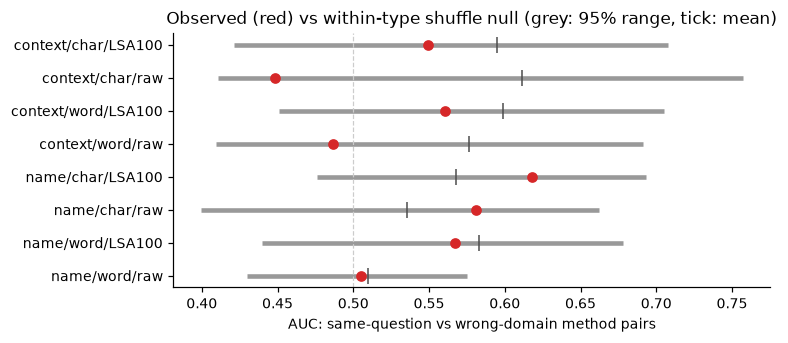

In [12]:
fig, ax = plt.subplots(figsize=(7, 3))
keys = list(NULLS)
for i, k in enumerate(keys):
    obs, null = NULLS[k]
    ax.plot([np.quantile(null, .025), np.quantile(null, .975)], [i, i], color="0.6", lw=3, solid_capstyle="butt")
    ax.plot(null.mean(), i, "|", color="0.3", ms=10)
    ax.plot(obs, i, "o", color="C3")
ax.axvline(0.5, color="0.8", lw=0.8, ls="--")
ax.set_yticks(range(len(keys)), ["/".join(k) for k in keys])
ax.set(xlabel="AUC: same-question vs wrong-domain method pairs",
       title="Observed (red) vs within-type shuffle null (grey: 95% range, tick: mean)")
fig.savefig(FIG / "sem_gt_auc_vs_null.png"); plt.show()

**Reading.** No representation separates same-question methods from wrong-domain methods better than the shuffled null: no observed AUC is above the null's 95% range, and every one-sided p is large. The context variants even fall below the null mean. Two further points:
- **The naive comparison would mislead.** Raw AUCs of about 0.58 look like a weak signal against 0.5, but the null reaches the same values through the best-pair scoring.
- **Attached context text doesn't help, and tends to hurt.** It mixes in evaluation boilerplate shared by unrelated methods.

**The test has little power.** The 177 pairs involve only about 26 distinct expected targets and 11 distinct wrong-domain targets, so they are not independent, and the null's standard deviation is about 0.07. Only a large effect would be detectable. The correct reading is therefore "no detectable separation", not proof that names carry no semantic signal. (An independent re-check found the same result when each pair is scored by its mean cosine instead of its best pair: AUC 0.56.)

The reference covers method-level relatedness only: the slots that match, mostly method names. It says nothing about descriptive types such as tasks or techniques, where §3 suggests lexical similarity is meaningful.

## 5. Trial clustering on semantics alone

**Setup.** Average-linkage agglomerative clustering on cosine distance, with 15 and 60 clusters (the level-0 and level-1 budgets), for the name + character n-gram representation, raw and LSA. For each run:
- **giant share:** the share of nodes in the largest cluster;
- **singletons;**
- **mean type purity:** the share of a cluster's most common type;
- **papers per cluster:** how many papers a cluster's members come from.

In [13]:
def trial(S, k):
    D = 1 - np.clip(S, 0, 1); np.fill_diagonal(D, 0)
    lab = AgglomerativeClustering(n_clusters=k, metric="precomputed", linkage="average").fit_predict(D)
    sizes = np.bincount(lab)
    purity = np.mean([collections.Counter(TY[lab == c]).most_common(1)[0][1] / sizes[c] for c in range(k)])
    papers = [len(set().union(*[ARTS[i] for i in np.where(lab == c)[0]])) for c in range(k)]
    return lab, {"giant share": sizes.max() / len(CORE), "singletons": int((sizes == 1).sum()),
                 "mean type purity": purity, "median papers per cluster": float(np.median(papers))}
TRIALS = {}
rows = []
for repr_ in ("raw", "LSA100"):
    for k in (15, 60):
        lab, r = trial(SIMS[("name", "char", repr_)], k); TRIALS[(repr_, k)] = lab
        rows.append({"repr": repr_, "clusters": k, **r})
pd.DataFrame(rows).set_index(["repr", "clusters"])

giant share  singletons  mean type purity  \
repr   clusters                                              
raw    15              0.996          13             0.950   
       60              0.841          24             0.823   
LSA100 15              0.389           0             0.396   
       60              0.075           0             0.428   

                 median papers per cluster  
repr   clusters                             
raw    15                              1.0  
       60                              2.0  
LSA100 15                             33.0  
       60                             24.0

In [14]:
lab = TRIALS[("LSA100", 15)]
deg = N.loc[CORE, "prov_articles"].map(len).to_numpy()
rows = []
for c in np.argsort(-np.bincount(lab)):
    idx = np.where(lab == c)[0]
    top = idx[np.argsort(-deg[idx])][:5]
    rows.append({"size": len(idx), "types": ", ".join(f"{t} {n}" for t, n in collections.Counter(TY[idx]).most_common(3)),
                 "most-shared members": "; ".join(N.at[CORE[i], "surface_form"][:22] for i in top)})
pd.DataFrame(rows)

,size,types,most-shared members
0,1548,"task 409, problem 355, technique 302",computational chemistr; computational physics; computational mater...
1,834,"technique 274, component 172, problem 124",Neural Equivariant Int; machine learning; MACE-MP-0; machine learn...
2,240,"technique 82, component 75, task 26",Gaussian approximation; Atomic Cluster Expansi; Graph Atomic Clust...
3,217,"technique 85, component 62, method 22",Geometry optimization; Random Forest; Allegro; Gradient clipping; ...
4,196,"method 73, component 61, technique 39",Message Passing Neural; graph neural network; ACE with message pas...
5,161,"task 55, problem 43, component 17",materials science; materials discovery; Materials Graph Networ; ba...
6,148,"component 54, technique 26, dataset 25",SchNet; ML‑IAP; PhysNet; GemNet; M3GNet
7,110,"technique 38, task 28, dataset 15",Matbench Discovery; Matbench-Discovery; MAE evaluation; 5-fold cro...
8,101,"task 41, dataset 16, problem 15",molecular dynamics; Molecular dynamics sim; Molecular dynamics sim...
9,95,"dataset 34, component 32, method 12",Ethanol; Aspirin; Benzene; JAX; LLM


**Reading:**
- **Raw TF-IDF chains.** Most node pairs share no character n-gram, so their similarity is about 0. Average linkage then merges everything into one cluster holding almost all nodes at 15 clusters, and still most nodes at 60. As a clustering signal on its own, raw lexical similarity is unusable.
- **LSA reduces the chaining.** The densified vectors spread nodes over many more clusters, and those clusters span many papers. But 15 clusters still leave one large cluster of generic computational/scientific terms.
  - The exact shares depend on the SVD seed: with 60 clusters the largest holds about 6.5–7.5% of nodes, and with 15 clusters about 39–57%, across seeds 0–2 in an independent re-check.
- **But the clusters are lexical themes.** They group things like 'molecular dynamics / simulation', 'MAE / energy MAE / force MAE', 'descriptors' or 'OC20 variants'. Type purity is low, so they mix types.
- **The method names are mixed in.** With no shared vocabulary they land in whatever theme their name happens to resemble, consistent with §4.

## 6. Conclusions

**Verified (computed above):**
- The only semantic information the export carries for concept nodes is their names (median 2–5 tokens), aliases on a small share of method nodes, and evaluation strings attached to datasets and metrics. There are no abstracts or descriptions.
- Lexical similarity:
  - partly encodes node type (about 2× chance) and paper identity (about 7× random);
  - adds links across papers for about half of the nodes that have a strong neighbour;
  - surfaces many duplicate entities across node types.
- It shows **no detectable** separation of same-question from wrong-domain methods beyond a within-type shuffle null, in any of the 8 representations. The test has low power: about 26 expected and 11 wrong-domain targets.
- Raw TF-IDF chains into a giant cluster under average linkage. LSA densification reduces this, though at 15 clusters one large generic-term cluster remains.

**What this means for the clustering method (P3):**
1. **Usable, but weak.** Names are a usable but weak semantic signal: informative for descriptive concepts (tasks, problems, techniques, components) and for entity resolution, and near-uninformative for relatedness between proper-named methods and datasets.
   - For those, meaning has to come from structure (`extends`, `evaluated_on`, shared tasks) or from text outside the export.
   - That outside text could be arXiv abstracts for the 36 papers with an id, or a pretrained embedding model. Both need an external download, which the brief neither forbids nor requires. This is an open decision.
2. **Use a dense projection.** If names are used, use a dense projection such as character n-gram LSA, not raw TF-IDF, to avoid chaining.
3. **Don't let the signal dominate.** It partly regroups by type and partly re-encodes paper identity, so its weight must be bounded and the type confound reported. A type-preserving null, as in §4, is the right control.
4. **The evaluation signal stays independent.** Ground-truth groups are human-curated and do not depend on these vectors. Even so, the ground truth is matched to nodes by name, so its coverage depends on name quality, which needs stating in the report.

**Assumed, not verified:**
- That ground-truth question membership is a fair proxy for "close in meaning" between methods.
- That character n-gram similarity is the strongest signal achievable from names without external models.